In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import time
from Functions.param_assoc import param_assoc
from Functions.kalman_filter import *

In [2]:
### Functions

# Function to calculate the CDF of the error
def cal_cdf(err, x):
    CDF = np.zeros(len(x))
    for iter in range(0, len(x)):
        CDF[iter] = np.sum(err <= x[iter])/len(err)
    return CDF


# Function to find LoS path using the estimated AoA and ToF
def find_los(t_est, theta_est, alpha_est, Doppler_est, aoa_ue):
    alpha_max = np.max(np.abs(alpha_est))
    
    while(len(t_est) > 0): # Continue until there is a path left to process
        l_ue = np.argmin(t_est) # Find the path index with the minimum transmit delay
        if (np.abs(theta_est[l_ue] - aoa_ue) > 7.5) or (np.abs(alpha_est[l_ue]) < 0.5*alpha_max): # Ignore the path if it is not coming from the UE or if it is too weak. LoS from the UE should be one of the strongest paths if not the strongest.
            t_est = np.delete(t_est, l_ue)
            theta_est = np.delete(theta_est, l_ue)
            alpha_est = np.delete(alpha_est, l_ue)
            Doppler_est = np.delete(Doppler_est, l_ue)
        else:
            break

    return t_est, theta_est, alpha_est, Doppler_est, l_ue


# Function to estimate the full channel estimates from combed channel estimates using interpolation (Support only for K_TC = 2 for now)
def interpolate_channel_estimates(H_combed, nPRB, N_ifft, K_TC):
    H_combed = np.concatenate([H_combed[N_ifft-6*nPRB:N_ifft], H_combed[0:6*nPRB]])
    K_srs = int(np.ceil(12*nPRB / K_TC))
    H = np.zeros([12*nPRB], dtype=np.complex128)
    n = 0

    if K_TC == 2:
        filt8_start = np.array([12288, 8192, 4096, 0, 0, 0, 0, 0])/16384
        filt8_end = np.array([4096, 8192, 12288, 16384])/16384
        filt8_middle2 = np.array([4096, 8192, 8192, 8192, 4096, 0, 0, 0])/16384
        filt8_middle4 = np.array([0, 0, 4096, 8192, 8192, 8192, 4096, 0])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt8_start)] = H[n:n+len(filt8_start)] + H_combed[k*K_TC]*filt8_start
            elif k == K_srs-1:
                H[n:n+len(filt8_end)] = H[n:n+len(filt8_end)] + H_combed[k*K_TC]*filt8_end
            elif np.mod(k, 2) == 1:
                H[n:n+len(filt8_middle2)] = H[n:n+len(filt8_middle2)] + H_combed[k*K_TC]*filt8_middle2
            elif np.mod(k, 2) == 0:
                H[n:n+len(filt8_middle4)] = H[n:n+len(filt8_middle4)] + H_combed[k*K_TC]*filt8_middle4
                n = k*K_TC

    elif K_TC == 4:
        filt16_start = np.array([12288, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_end = np.array([4096, 8192, 8192, 8192, 12288, 16384, 16384, 16384, 0, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_middle = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt16_start)] = H[n:n+len(filt16_start)] + H_combed[k*K_TC]*filt16_start
            elif k == K_srs-1:
                if n+len(filt16_end) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_end[0:len(H)-n]
                else:
                    H[n:n+len(filt16_end)] = H[n:n+len(filt16_end)] + H_combed[k*K_TC]*filt16_end
            else:
                if n+len(filt16_middle) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_middle[0:len(H)-n]
                else:
                    H[n:n+len(filt16_middle)] = H[n:n+len(filt16_middle)] + H_combed[k*K_TC]*filt16_middle
                n = k*K_TC

    elif K_TC == 8:
        filt16_start = np.array([12288, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_end = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 12288, 16384, 16384, 16384, 16384, 16384, 16384, 16384])/16384
        filt16_middle = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt16_start)] = H[n:n+len(filt16_start)] + H_combed[k*K_TC]*filt16_start
            elif k == K_srs-1:
                if n+len(filt16_end) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_end[0:len(H)-n]
                else:
                    H[n:n+len(filt16_end)] = H[n:n+len(filt16_end)] + H_combed[k*K_TC]*filt16_end
            else:
                if n+len(filt16_middle) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_middle[0:len(H)-n]
                else:
                    H[n:n+len(filt16_middle)] = H[n:n+len(filt16_middle)] + H_combed[k*K_TC]*filt16_middle
                n = k*K_TC
            

    H = np.concatenate([H[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), H[0:6*nPRB]])
    
    return H

In [3]:
### Signal and system parameters

D = np.array([20, 20, 20]) # distance of the UE from the gNB (in m)
AoA_UE = np.array([0, 0, 0, 0, 0, 0, 0]) # AoA of the UE (in radians)
c = 299792458
f_c = 3.6192e9
bandwidth = 20e6
scs = 30e3
K_TC = 2 # This is the SRS transmission comb

if bandwidth == 20e6:
    f_s = 30.72e6
    N_ifft = 1024
    nPRB = 51
    N_cp = 72
    occ_bandwidth = 12*nPRB*scs
    print("Bandwidth is 20 MHz")

elif bandwidth == 40e6:
    f_s = 61.44e6
    N_ifft = 2048
    nPRB = 106
    N_cp = 144
    occ_bandwidth = 12*nPRB*scs
    print("Bandwidth is 40 MHz")

elif bandwidth == 80e6:
    f_s = 122.88e6
    N_ifft = 4096
    nPRB = 217
    N_cp = 288
    occ_bandwidth = 12*nPRB*scs
    print("Bandwidth is 80 MHz")

osf = 8
N_ant = 4
d_ant = 1/2*np.arange(0, N_ant, 1) # inter-element distance (in terms of wavelength)
P_t = 0.1 # Watt
K = 1.380649e-23
T = 298
noise_var = K*bandwidth*T
srs_period = 20e-3 # SRS transmission period in seconds

trajectories = np.array(['Trajectory_1', 'Trajectory_2'])
iter_traj = 0 # This variable is used to select the trajectory for simulation. It can take values 0, 1, or 2.

### Channel parameters
chan_params = np.load('/home/bkumar2/Documents/Research/ISAC/Python_Scripts_CellSense2.0/Simulation/Datasets/Outdoor_scenario/' + trajectories[iter_traj] + '/ISAC_ray_tracing_chan.npy')
positions = np.load('/home/bkumar2/Documents/Research/ISAC/Python_Scripts_CellSense2.0/Simulation/Datasets/Outdoor_scenario/' + trajectories[iter_traj] + '/ISAC_locations.npy')
obj_params = np.load('/home/bkumar2/Documents/Research/ISAC/Python_Scripts_CellSense2.0/Simulation/Datasets/Outdoor_scenario/' + trajectories[iter_traj] + '/obj_params.npy')

visibility = obj_params[:, 3] # This array indicates the ground truth of object visibility to the BS.

K = 500
tau = chan_params[:, 2, :] # Transmit delay in s 
theta = chan_params[:, 0, :] # AoA in radians
Doppler = chan_params[:, 1, :] # Doppler in Hz (converted from m/s)
pathgain = chan_params[:, 3, :] # Pathgain in absolute value

L = np.shape(tau)[1]

for k in range(0, K):
    order = np.argsort(pathgain[k, :])[::-1]
    tau[k, :] = tau[k, order]
    theta[k, :] = theta[k, order]
    Doppler[k, :] = Doppler[k, order]
    pathgain[k, :] = pathgain[k, order]

# Repeat the same values K times for averaging (Monte carlo simulation)
# tau = np.tile(np.reshape(tau, [1, len(tau)]), [K, 1])
# theta = np.tile(np.reshape(theta, [1, len(theta)]), [K, 1])
theta = theta + np.pi
theta = np.pi/2 - theta
theta = (theta + np.pi) % (2 * np.pi) - np.pi
obj_params[:, 0] = np.pi/180*obj_params[:, 0]  # This variable stores the AoA of the object of interest
obj_params[:, 0] = obj_params[:, 0] + np.pi
obj_params[:, 0] = np.pi/2 - obj_params[:, 0]
obj_params[:, 0] = (obj_params[:, 0] + np.pi) % (2 * np.pi) - np.pi
obj_params[:, 0] = 180/np.pi*obj_params[:, 0]
# Doppler = np.tile(np.reshape(Doppler, [1, len(Doppler)]), [K, 1])
pathgain = P_t*pathgain/noise_var

Bandwidth is 20 MHz


In [9]:
np.sqrt(4790)

69.2098258919931

In [4]:
### Generate received signal

K = 500
gen_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
rcvd_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples
phase = np.random.rand(L)

obj_pos = np.zeros([K+1, 2])
obj_pos[0, :] = np.array([-4, 11])
obj_vel = np.array([-1, -0.25])
obj_phase = np.random.rand(1)
RCS = 100

obj_theta = np.zeros(K)
obj_tau = np.zeros(K)
obj_Doppler = np.zeros(K)
obj_pathgain = np.zeros(K)

H_full = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)

for k in range(0, K):
    obj_theta[k] = np.arctan2(obj_pos[k, 0], obj_pos[k, 1])
    obj_tau[k] = np.linalg.norm(obj_pos[k, :])/c + np.linalg.norm(np.array([0, D[iter_traj]]) - obj_pos[k, :])/c # Total length of the signal path
    obj_Doppler[k] = np.dot(obj_vel, np.array([0, 0]) - obj_pos[k, :])/np.linalg.norm(np.array([0, 0]) - obj_pos[k, :])*f_c/c + \
                      np.dot(obj_vel, np.array([0, D[iter_traj]]) - obj_pos[k, :])/np.linalg.norm(np.array([0, D[iter_traj]]) - obj_pos[k, :])*f_c/c  # Doppler shift due to the relative motion of the object w.r.t. the BS and UE
    obj_pathgain[k] = RCS*P_t/noise_var*(1/(4*np.pi*(np.linalg.norm(np.array([0, D[iter_traj]]) - obj_pos[k, :])**2)))*(c/(4*np.pi*f_c*np.linalg.norm(obj_pos[k, :])))**2

    print("Object position: ", obj_pos[k, :], " Object AoA: ", obj_theta[k]*180/np.pi, " Object delay: ", obj_tau[k]*1e9, " Object Doppler: ", obj_Doppler[k], " Object pathgain: ", obj_pathgain[k])

    Xn = np.zeros([12*nPRB], dtype=np.complex128)
    m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
    Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)
    Xn[np.setdiff1d(np.arange(0, 12*nPRB, 1), np.arange(0, 12*nPRB, K_TC))] = np.exp(1j*(np.pi*np.random.randint(0, 4, [12*nPRB - len(m)])/2 + np.pi/4)) # Remaining subcarriers transmit QPSK symbols
    Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
    Xn = np.reshape(Xn, [N_ifft, 1])

    X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
    X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
    X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

    t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
    n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
    n = np.reshape(n, [N_ifft, 1])
    n = np.tile(n, [1, N_ifft])

    # This loop just generates the OFDM samples in time domain
    temp_xn = np.tile(Xn, [1, N_ifft])

    for l in range(0, L):
        if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                        np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

            gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau[k], [1, N_ifft]), [N_ifft, 1])), axis=0)
    gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

    # Add the AWGN noise to the generated samples
    rcvd_signal[k, :, :] = gen_signal[k, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))

    rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal[k, :, :], axis=1)
    for i in range(0, N_ifft):
        if Xn[i] == 0:
            H_full[k, :, i] = np.zeros([N_ant])
        else:
            H_full[k, :, i] = rcvd_sig_freq[:, i]*np.conjugate(np.tile(Xn[i], [N_ant]))

    obj_pos[k+1, :] = obj_pos[k, :] + obj_vel*srs_period
    phase = phase + Doppler[0, :]*srs_period
    obj_phase = obj_phase + obj_Doppler[k]*srs_period


Object position:  [-4. 11.]  Object AoA:  -19.98310652189998  Object delay:  71.89492976676462  Object Doppler:  -8.950273291676032  Object pathgain:  31620.213899783957
Object position:  [-4.02  10.995]  Object AoA:  -20.083460275021977  Object delay:  71.94449425336293  Object Doppler:  -8.988093297623468  Object pathgain:  31527.186097068185
Object position:  [-4.04 10.99]  Object AoA:  -20.18377680074093  Object delay:  71.9942675308812  Object Doppler:  -9.025838901474273  Object pathgain:  31434.175753831947
Object position:  [-4.06  10.985]  Object AoA:  -20.284055505075436  Object delay:  72.04424918816909  Object Doppler:  -9.063510104083942  Object pathgain:  31341.18558827693
Object position:  [-4.08 10.98]  Object AoA:  -20.38429579541872  Object delay:  72.09443881408389  Object Doppler:  -9.101106907301945  Object pathgain:  31248.218295866132
Object position:  [-4.1   10.975]  Object AoA:  -20.484497080558548  Object delay:  72.14483599749569  Object Doppler:  -9.1386293

In [ ]:
# ### Generate received signal

# K = 500
# gen_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
# rcvd_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples

# obj_theta = obj_params[:, 0]
# obj_tau = obj_params[:, 1]
# obj_Doppler = obj_params[:, 2]
# obj_detect = obj_params[:, 3]

# H_full = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)

# for k in range(0, K):
    
#     print(" Object AoA: ", obj_theta[k], " Object delay: ", obj_tau[k], " Object Doppler: ", obj_Doppler[k])

#     Xn = np.zeros([12*nPRB], dtype=np.complex128)
#     m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
#     Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)
#     Xn[np.setdiff1d(np.arange(0, 12*nPRB, 1), np.arange(0, 12*nPRB, K_TC))] = np.exp(1j*(np.pi*np.random.randint(0, 4, [12*nPRB - len(m)])/2 + np.pi/4)) # Remaining subcarriers transmit QPSK symbols
#     Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
#     Xn = np.reshape(Xn, [N_ifft, 1])

#     X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
#     X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
#     X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

#     t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
#     n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
#     n = np.reshape(n, [N_ifft, 1])
#     n = np.tile(n, [1, N_ifft])

#     # This loop just generates the OFDM samples in time domain
#     temp_xn = np.tile(Xn, [1, N_ifft])
#     phase = -f_c*tau[k, :]

#     for l in range(0, L):
#         if np.isnan(Doppler[k,l]):
#             Doppler[k,l] = 0
            
#         if ((theta[k, l] >= -np.pi/2) and (theta[k, l] < np.pi/2)) and (pathgain[k, l] > 1):
#             temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[k, l]) * np.exp(1j*2*np.pi*phase[l]) * \
#                         np.exp(1j*2*np.pi*Doppler[k, l]*t) * \
#                         np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[k, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

#             gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[k, l])), [N_ant, 1]), [1, N_ifft]) * \
#                                                         np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

#     # Add the AWGN noise to the generated samples
#     rcvd_signal[k, :, :] = gen_signal[k, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))

#     rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal[k, :, :], axis=1)
#     for i in range(0, N_ifft):
#         if Xn[i] == 0:
#             H_full[k, :, i] = np.zeros([N_ant])
#         else:
#             H_full[k, :, i] = rcvd_sig_freq[:, i]*np.conjugate(np.tile(Xn[i], [N_ant]))



 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object AoA:  -90.0  Object delay:  0.0  Object Doppler:  0.0
 Object 

In [5]:
### Channel estimation

# Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=2)

# Estimate the channel using X_pilot as pilot symbols
H_combed = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) 

for i in range(0, N_ifft):
    if X_pilot[i] == 0:
        H_combed[:, :, i] = np.zeros([K, N_ant])
    else:
        H_combed[:, :, i] = rcvd_sig_freq[:, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_ant]))

H = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)
for k in range(0, K):
    for n_ant in range(0, N_ant):
        H[k, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_ant, :], nPRB, N_ifft, K_TC)

In [6]:
### Parameter estimation using mD-Track (ToF+AoA from single symbol and Doppler using 4 symbols)

m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence)
Xn = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
Xn = np.reshape(Xn, [N_ifft, 1])

err_Doppler = np.zeros([K])
err_theta = np.zeros([K])
err_tau = np.zeros([K])
detect = np.zeros([K])
est_Doppler = np.zeros([K])
est_theta = np.zeros([K])
est_tau = np.zeros([K])

# First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
complex_rxsym0 = H[:, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym0 = np.concatenate([complex_rxsym0[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym0[:, N_ifft//2:N_ifft]], axis=1)
complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=1)
complex_rxsym1 = H[:, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym1 = np.concatenate([complex_rxsym1[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym1[:, N_ifft//2:N_ifft]], axis=1)
complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=1)
complex_rxsym2 = H[:, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym2 = np.concatenate([complex_rxsym2[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym2[:, N_ifft//2:N_ifft]], axis=1)
complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=1)
complex_rxsym3 = H[:, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym3 = np.concatenate([complex_rxsym3[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym3[:, N_ifft//2:N_ifft]], axis=1)
complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=1)

# This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os)

L = 5 # No. of paths estimated
parameters = np.zeros([4, L, K], dtype=np.complex128) # Save the estimated channel parameters in this array
L_K = np.zeros([K], dtype=np.int64)

T_obs = 4

for iter0 in range(-10, K-10):
    iter1 = iter0 + 10

    est_mean_time0 = complex_time0[iter1, :]
    est_mean_time1 = complex_time1[iter1, :]
    est_mean_time2 = complex_time2[iter1, :]
    est_mean_time3 = complex_time3[iter1, :]

    mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

    resolve = 5 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
    
    # Search space for the parameters
    t_search = np.arange(-50, 50, 1)
    theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)

    for iter in range(0, resolve):

        beam_strength = np.zeros([len(theta_search), L])
        caf_time = np.zeros([len(t_search), L])
        
        for l in range(0, L):

            # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
            if iter > 0:
                generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l, iter1]))), [N_ant, 1]), [1, osf*N_ifft])

                generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l, iter1])), axis=1)
                                                
                generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l, iter1])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])

                generated_sig = parameters[3, l, iter1]*generated_sig
                mean_chan_subcarrier = generated_sig + residual_sig

            if iter > 2:
                theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l, iter1])
                
            est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

            # mean_chan = np.average(est_mean_rxsym, axis=1)

            # START - Code for beam sweeping here and finding the strongest direction.

            for i in range(0, len(theta_search)):
                beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)

            max_idx = np.argmax(beam_strength[:, l])
            max_theta = theta_search[max_idx] 

            parameters[0, l, iter1] = max_theta
            # END - Code for beam sweeping here and finding the strongest direction.

            # START - Code for estimating the transmit delay using CAF (Cross Ambiguity function)

            n = np.arange(0, osf*N_ifft, 1)

            combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])*mean_chan_subcarrier, axis=0)

            max_caf = 0
            for t in range(0, len(t_search)):
                caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[0:osf*N_ifft])) 
                
                if caf_time[t,l] > max_caf:
                    t_best = t
                    max_caf = caf_time[t,l]

            parameters[2, l, iter1] = t_search[t_best]

            # END - Code for estimating the transmit delay using CAF

            # START - Code that is used to regenerate the signal using the estimated parameters

            generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])

            generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1)
                            
            alpha = np.average(mean_chan_subcarrier/generated_sig)

            parameters[3, l, iter1] = alpha

            generated_sig = alpha*generated_sig

            residual_sig = mean_chan_subcarrier - generated_sig

            mean_chan_subcarrier = residual_sig

            # END - Code that is used to regenerate the signal using the estimated parameters

    # print(np.abs(parameters[3, :, iter1]))
    # print(np.real(parameters[2, :, iter1]))
    # print(np.real(parameters[0, :, iter1])*180/np.pi)

    t_est = np.real(parameters[2, :, iter1])
    theta_est = np.real(parameters[0, :, iter1])*180/np.pi
    alpha_est = np.abs(parameters[3, :, iter1])
    Doppler_est = np.real(parameters[1, :, iter1])
    t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])
    
    if len(t_est) == 0:
        l_ue = np.argmin(np.real(parameters[2, :, iter1]))
        t_offset = np.real(parameters[2, l_ue, iter1])
        L_K[iter1] = L
    else:
        t_offset = t_est[l_ue]
        parameters[0, 0:len(t_est), iter1] = theta_est*np.pi/180
        parameters[1, 0:len(t_est), iter1] = Doppler_est
        parameters[2, 0:len(t_est), iter1] = t_est
        parameters[3, 0:len(t_est), iter1] = alpha_est
        L_K[iter1] = len(t_est)
        

    complex_time0[iter1, :] = np.roll(complex_time0[iter1, :], -int(t_offset))
    complex_time1[iter1, :] = np.roll(complex_time1[iter1, :], -int(t_offset))
    complex_time2[iter1, :] = np.roll(complex_time2[iter1, :], -int(t_offset))
    complex_time3[iter1, :] = np.roll(complex_time3[iter1, :], -int(t_offset))

    parameters[2, :, iter1] = parameters[2, :, iter1] - t_offset*np.ones(L)
    # print(np.abs(parameters[3, 0:L_K[iter1], iter1]))
    # print(np.real(parameters[2, 0:L_K[iter1], iter1])/(osf*f_s)*1e9)
    # print(np.real(parameters[0, 0:L_K[iter1], iter1])*180/np.pi)
    # print("- - - - - - - - - - -\n")

    if iter0 >= 0:
        print("---------------------Start of {}th symbol------------------------".format(iter0))
        
        est_mean_time0 = np.concatenate([complex_time0[iter0, :], complex_time0[iter0+1, :], complex_time0[iter0+4, :], complex_time0[iter0+10, :]])
        est_mean_time1 = np.concatenate([complex_time1[iter0, :], complex_time1[iter0+1, :], complex_time1[iter0+4, :], complex_time1[iter0+10, :]])
        est_mean_time2 = np.concatenate([complex_time2[iter0, :], complex_time2[iter0+1, :], complex_time2[iter0+4, :], complex_time2[iter0+10, :]])
        est_mean_time3 = np.concatenate([complex_time3[iter0, :], complex_time3[iter0+1, :], complex_time3[iter0+4, :], complex_time3[iter0+10, :]])

        mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

        resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
        L = 5 # No. of paths estimated

        # Search space for the parameters
        f_search = np.arange(-25, 24, 1)
        
        for iter in range(0, resolve):

            caf_freq = np.zeros([len(f_search), L_K[iter0]])
            
            for l in range(0, L_K[iter0]):

                # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                if iter > 0:
                    generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l, iter0]))), [N_ant, 1]), [1, T_obs*osf*N_ifft])

                    generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1), \
                                                    np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1), \
                                                    np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1), \
                                                    np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1)], axis=1)
                    
                    generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l, iter0])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                    np.exp(1j*2*np.pi*np.real(parameters[1, l, iter0])*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l, iter0])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                    np.exp(1j*2*np.pi*np.real(parameters[1, l, iter0])*4*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l, iter0])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                    np.exp(1j*2*np.pi*np.real(parameters[1, l, iter0])*10*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l, iter0])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)

                    generated_sig = parameters[3, l, iter0]*generated_sig
                    mean_chan_subcarrier = generated_sig + residual_sig
        
                est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

                # START - Code for estimating the Doppler using CAF (Cross Ambiguity function)

                n = np.arange(0, osf*N_ifft, 1)

                combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l, iter0]))), [N_ant, 1]), [1, T_obs*osf*N_ifft])*mean_chan_subcarrier, axis=0)
                    
                max_caf = 0
                shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym), int(np.real(parameters[2, l, iter0])))*combined_chan[0:osf*N_ifft], \
                                                        np.roll(np.conj(time_gensym), int(np.real(parameters[2, l, iter0])))*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                        np.roll(np.conj(time_gensym), int(np.real(parameters[2, l, iter0])))*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                        np.roll(np.conj(time_gensym), int(np.real(parameters[2, l, iter0])))*combined_chan[3*osf*N_ifft:4*osf*N_ifft]])
                for f in range(0, len(f_search)):
                    caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                np.exp(-1j*2*np.pi*f_search[f]*srs_period)*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                np.exp(-1j*2*np.pi*f_search[f]*4*srs_period)*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                np.exp(-1j*2*np.pi*f_search[f]*10*srs_period)*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))])))
                    if caf_freq[f,l] > max_caf:
                        f_best = f
                        max_caf = caf_freq[f,l]

                parameters[1, l, iter0] = f_search[f_best]
                
                # END - Code for estimating the Doppler using CAF

                # START - Code that is used to regenerate the signal using the estimated parameters

                generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l, iter0]))), [N_ant, 1]), [1, T_obs*osf*N_ifft])

                generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1), \
                                                np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1), \
                                                np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1), \
                                                np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l, iter0])), axis=1)], axis=1)

                generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*f_search[f_best]*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*f_search[f_best]*4*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*f_search[f_best]*10*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)

                alpha = np.average(mean_chan_subcarrier/generated_sig)

                parameters[3, l, iter0] = alpha

                generated_sig = alpha*generated_sig

                residual_sig = mean_chan_subcarrier - generated_sig

                mean_chan_subcarrier = residual_sig

                # END - Code that is used to regenerate the signal using the estimated parameters

        t_est = np.real(parameters[2, 0:L_K[iter0], iter0])/(osf*f_s)*1e9
        theta_est = np.real(parameters[0, 0:L_K[iter0], iter0])*180/np.pi
        alpha_est = np.abs(parameters[3, 0:L_K[iter0], iter0])
        Doppler_est = np.real(parameters[1, 0:L_K[iter0], iter0])
        t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

        err_max = 100
        for l in range(0, len(t_est)):
            if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max):
                err_theta[iter0] = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                err_tau[iter0] = np.abs(t_est[l] - 1e9*obj_tau[iter0] + 1e9*tau[0, 0])
                err_Doppler[iter0] = np.abs(Doppler_est[l] - obj_Doppler[iter0])
                detect[iter0] = 1

                err_max = np.abs(np.real(parameters[0, l, iter0])*180/np.pi - 180/np.pi*obj_theta[iter0])
                l_obj = l

        print("Estimated AoA for all paths: ", np.real(parameters[0, 0:L_K[iter0], iter0])*180/np.pi)
        print("Estimated Doppler for all paths: ", np.real(parameters[1, 0:L_K[iter0], iter0]))
        print("Estimated ToA for all paths: ", np.real(parameters[2, 0:L_K[iter0], iter0])/(osf*f_s)*1e9)
        print("Estimated strength for all paths: ", np.abs(parameters[3, 0:L_K[iter0], iter0]))
        print(l_ue)
        print(t_est)

        if (err_max < 100) and len(t_est) > 0:
            print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

            print(l_obj)
            
            est_Doppler[iter0] = Doppler_est[l_obj]
            est_theta[iter0] = theta_est[l_obj]
            est_tau[iter0] = t_est[l_obj] - t_est[l_ue]

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -8.0670353  -68.22760379  85.89804311  72.14705602 -81.97859087]
Estimated Doppler for all paths:  [ 0.  0.  0. -9.  0.]
Estimated ToA for all paths:  [ 0.          4.06901042 97.65625     0.         73.2421875 ]
Estimated strength for all paths:  [229.53333388  43.50714004  33.3238126   50.90550833  31.7716119 ]
0
[]
---------------------Start of 1th symbol------------------------
Estimated AoA for all paths:  [ -8.63999309 -71.66535056  88.76283208  75.58480279  88.76283208]
Estimated Doppler for all paths:  [  0.  -1.   0. -21.   0.]
Estimated ToA for all paths:  [  0.           8.13802083 101.72526042   8.13802083  69.17317708]
Estimated strength for all paths:  [266.76267592  46.14309654  33.332637    25.38880311  28.21148464]
0
[]
---------------------Start of 2th symbol------------------------
Estimated AoA for all paths:  [ -5.20224632 -76.82197071 -18.9532334  -76.24901292 -82.5515

In [8]:
np.sum(detect)

169.0

In [9]:
### Parameter estimation using mD-Track (4 OFDM symbols used together)

m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence)
Xn = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
Xn = np.reshape(Xn, [N_ifft, 1])

err_Doppler_4 = np.zeros([K])
err_theta_4 = np.zeros([K])
err_tau_4 = np.zeros([K])
detect_4 = np.zeros([K])
est_Doppler_4 = np.zeros([K])
est_theta_4 = np.zeros([K])
est_tau_4 = np.zeros([K])

# First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
complex_rxsym0 = H[:, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym0 = np.concatenate([complex_rxsym0[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym0[:, N_ifft//2:N_ifft]], axis=1)
complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=1)
complex_rxsym1 = H[:, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym1 = np.concatenate([complex_rxsym1[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym1[:, N_ifft//2:N_ifft]], axis=1)
complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=1)
complex_rxsym2 = H[:, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym2 = np.concatenate([complex_rxsym2[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym2[:, N_ifft//2:N_ifft]], axis=1)
complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=1)
complex_rxsym3 = H[:, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym3 = np.concatenate([complex_rxsym3[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym3[:, N_ifft//2:N_ifft]], axis=1)
complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=1)

# This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os)

T_obs = 4

for iter0 in range(0, K-10):
    print("---------------------Start of {}th symbol------------------------".format(iter0))
    
    est_mean_time0 = np.concatenate([complex_time0[iter0, :], complex_time0[iter0+1, :], complex_time0[iter0+4, :], complex_time0[iter0+10, :]])
    est_mean_time1 = np.concatenate([complex_time1[iter0, :], complex_time1[iter0+1, :], complex_time1[iter0+4, :], complex_time1[iter0+10, :]])
    est_mean_time2 = np.concatenate([complex_time2[iter0, :], complex_time2[iter0+1, :], complex_time2[iter0+4, :], complex_time2[iter0+10, :]])
    est_mean_time3 = np.concatenate([complex_time3[iter0, :], complex_time3[iter0+1, :], complex_time3[iter0+4, :], complex_time3[iter0+10, :]])

    mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

    resolve = 5 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
    L = 5 # No. of paths estimated
    parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

    # Search space for the parameters
    f_search = np.arange(-24, 24, 1)
    t_search = np.arange(-50, 50, 1)
    theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
    
    for iter in range(0, resolve):

        beam_strength = np.zeros([len(theta_search), L])
        caf_freq = np.zeros([len(f_search), L])
        caf_time = np.zeros([len(t_search), L])
        
        for l in range(0, L):

            # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
            if iter > 0:
                generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, T_obs*osf*N_ifft])

                generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
                
                generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                np.exp(1j*2*np.pi*np.real(parameters[1, l])*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                np.exp(1j*2*np.pi*np.real(parameters[1, l])*4*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                np.exp(1j*2*np.pi*np.real(parameters[1, l])*10*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)

                generated_sig = parameters[3, l]*generated_sig
                mean_chan_subcarrier = generated_sig + residual_sig

            if iter > 2:
                theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                
            est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

            # mean_chan = np.average(est_mean_rxsym, axis=1)

            # START - Code for beam sweeping here and finding the strongest direction.

            for i in range(0, len(theta_search)):
                beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)

                # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                
            max_idx = np.argmax(beam_strength[:, l])
            max_theta = theta_search[max_idx] 

            parameters[0, l] = max_theta
            # END - Code for beam sweeping here and finding the strongest direction.

            # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)

            n = np.arange(0, osf*N_ifft, 1)

            combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, T_obs*osf*N_ifft])*mean_chan_subcarrier, axis=0)

            max_caf = 0
            for t in range(0, len(t_search)):
                caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[0:osf*N_ifft])) + \
                                 np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[osf*N_ifft:2*osf*N_ifft])) + \
                                 np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[2*osf*N_ifft:3*osf*N_ifft])) + \
                                 np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[3*osf*N_ifft:4*osf*N_ifft]))
                
                if caf_time[t,l] > max_caf:
                    t_best = t
                    max_caf = caf_time[t,l]
                
            max_caf = 0
            shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[0:osf*N_ifft], \
                                                    np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                    np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                    np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[3*osf*N_ifft:4*osf*N_ifft]])
            for f in range(0, len(f_search)):
                caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                               np.exp(-1j*2*np.pi*f_search[f]*srs_period)*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                               np.exp(-1j*2*np.pi*f_search[f]*4*srs_period)*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                               np.exp(-1j*2*np.pi*f_search[f]*10*srs_period)*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))])))
                if caf_freq[f,l] > max_caf:
                    f_best = f
                    max_caf = caf_freq[f,l]

            # idx = np.argmax(caf[:, :, l])
            # f_best, t_best = np.unravel_index(idx, caf[:, :, l].shape)

            parameters[1, l] = f_search[f_best]
            parameters[2, l] = t_search[t_best]

            # END - Code for estimating the transmit delay and Doppler using CAF

            # START - Code that is used to regenerate the signal using the estimated parameters

            generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, T_obs*osf*N_ifft])

            generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1), \
                                            np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], t_search[t_best], axis=1), \
                                            np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], t_search[t_best], axis=1), \
                                            np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], t_search[t_best], axis=1)], axis=1)

            generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                          np.exp(1j*2*np.pi*f_search[f_best]*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                          np.exp(1j*2*np.pi*f_search[f_best]*4*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                          np.exp(1j*2*np.pi*f_search[f_best]*10*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)

            alpha = np.average(mean_chan_subcarrier/generated_sig)

            parameters[3, l] = alpha

            generated_sig = alpha*generated_sig

            residual_sig = mean_chan_subcarrier - generated_sig

            mean_chan_subcarrier = residual_sig

            # END - Code that is used to regenerate the signal using the estimated parameters

    t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
    theta_est = np.real(parameters[0, :])*180/np.pi
    alpha_est = np.abs(parameters[3, :])
    Doppler_est = np.real(parameters[1, :])
    t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

    err_max = 100
    for l in range(0, len(t_est)):
        if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max):
            err_theta_4[iter0] = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
            err_tau_4[iter0] = np.abs(t_est[l] - 1e9*obj_tau[iter0])
            err_Doppler_4[iter0] = np.abs(Doppler_est[l] - obj_Doppler[iter0])
            detect_4[iter0] = 1

            err_max = np.abs(np.real(parameters[0, l])*180/np.pi - 180/np.pi*obj_theta[iter0])
            l_obj = l

    print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
    print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
    print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
    print("Estimated strength for all paths: ", np.abs(parameters[3, :]))
    print(l_ue)
    print(t_est)

    if (err_max < 100) and len(t_est) > 0:
        print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

        print(l_obj)
        
        est_Doppler_4[iter0] = Doppler_est[l_obj]
        est_theta_4[iter0] = theta_est[l_obj]
        est_tau_4[iter0] = t_est[l_obj] - t_est[l_ue]

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.61858396 -18.9532334  -80.83267528 -80.83267528 -82.55154866]
Estimated Doppler for all paths:  [ 0. -9.  1.  0.  0.]
Estimated ToA for all paths:  [ 65.10416667  73.2421875   89.51822917 174.96744792 138.34635417]
Estimated strength for all paths:  [221.42997786 176.53030018  13.07097415  28.3693444   22.23434672]
0
[ 65.10416667  73.2421875   89.51822917 174.96744792 138.34635417]
Object is detected for this symbol with -19.98310652189998 AoA, 71.89492976676462 ToA, -8.950273291676032 Doppler of the object
1
---------------------Start of 1th symbol------------------------
Estimated AoA for all paths:  [ -2.91041514 -18.38027561 -79.68675969 -80.25971748 -81.97859087]
Estimated Doppler for all paths:  [ 0. -9.  0.  0.  0.]
Estimated ToA for all paths:  [ 65.10416667  73.2421875   85.44921875 170.8984375  138.34635417]
Estimated strength for all paths:  [228.88679033 163.14785125  25.792

In [ ]:
dynamic_params = np.zeros([2, 5, 3])
timestamps = np.zeros([2, 5])
est_pos_w_Dopp = np.zeros([K, 2])
est_pos_wo_Dopp = np.zeros([K, 2])
x_w_Dopp = np.zeros([4, 1])
P_w_Dopp = np.zeros([4, 4])
x_wo_Dopp = np.zeros([4, 1])
P_wo_Dopp = np.zeros([4, 4])

for k in range(0, K-10):
    if detect_1[k] == 1:
        meas_pos = est_pos(D[iter_traj], l_hat=est_tau_1[k]*1e-9*c, theta_hat=est_theta_1[k]*np.pi/180-AoA_UE[iter_traj])
        dynamic_params[1, 0, 0] = est_tau_1[k]
        dynamic_params[1, 0, 1] = est_theta_1[k]
        dynamic_params[1, 0, 2] = est_Doppler_1[k]
        timestamps[0, 0] = timestamps[1, 0]
        timestamps[1, 0] = k*srs_period

        if x_w_Dopp[0, 0] == 0:
            x_w_Dopp[0:2, 0] = meas_pos
            x_w_Dopp[2:4, 0] = np.zeros(2)
            P_w_Dopp[:, :] = np.diag([10, 10, 1, 1]) 
            x_wo_Dopp[0:2, 0] = meas_pos
            x_wo_Dopp[2:4, 0] = np.zeros(2)
            P_wo_Dopp[:, :] = np.diag([10, 10, 1, 1]) 

        else:
            x_wo_Dopp, P_wo_Dopp = kalman_filter_wo_doppler(x_wo_Dopp, P_wo_Dopp, dynamic_params, D[iter_traj], AoA_UE[iter_traj], timestamps, 0)
            # x_w_Dopp, P_w_Dopp = kalman_filter_w_doppler(x_w_Dopp, P_w_Dopp, dynamic_params, D[iter_traj], AoA_UE[iter_traj], timestamps, 0, f_c, c)

        est_pos_w_Dopp[k, :] = x_w_Dopp[0:2, 0]
        est_pos_wo_Dopp[k, :] = x_wo_Dopp[0:2, 0]

detect_idx = np.where(detect_1 == 1)

plt.scatter(est_pos_wo_Dopp[detect_idx, 0], est_pos_wo_Dopp[detect_idx, 1], color='g', marker='*', label='Estimated positions (KF+CellSense)', linewidths=5)
# plt.scatter(est_pos_w_Dopp[detect_idx, 0], est_pos_w_Dopp[detect_idx, 1], color='m', marker='s', label='Estimated positions (KF+Doppler+CellSense)', linewidths=5)
plt.scatter(obj_pos[detect_idx, 0], obj_pos[detect_idx, 1], color='k', marker='s', label='Ground Truth positions', linewidths=5)

rmse_wo_Dopp = np.sqrt(np.sum((est_pos_wo_Dopp[detect_idx, :] - obj_pos[detect_idx, :])**2)/len(detect_idx[0]))
# rmse_w_Dopp = np.sqrt(np.sum((est_pos_w_Dopp[detect_idx, :] - obj_pos[detect_idx, :])**2)/len(detect_idx[0]))

print(rmse_wo_Dopp)
# print(rmse_w_Dopp)

In [23]:
### Parameter estimation using mD-Track (Single OFDM symbol)

m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence)
Xn = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
Xn = np.reshape(Xn, [N_ifft, 1])

err_Doppler_1 = np.zeros([K])
err_theta_1 = np.zeros([K])
err_tau_1 = np.zeros([K])
detect_1 = np.zeros([K])
est_Doppler_1 = np.zeros([K])
est_theta_1 = np.zeros([K])
est_tau_1 = np.zeros([K])

# First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
complex_rxsym0 = H[:, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym0 = np.concatenate([complex_rxsym0[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym0[:, N_ifft//2:N_ifft]], axis=1)
complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=1)
complex_rxsym1 = H[:, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym1 = np.concatenate([complex_rxsym1[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym1[:, N_ifft//2:N_ifft]], axis=1)
complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=1)
complex_rxsym2 = H[:, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym2 = np.concatenate([complex_rxsym2[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym2[:, N_ifft//2:N_ifft]], axis=1)
complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=1)
complex_rxsym3 = H[:, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym3 = np.concatenate([complex_rxsym3[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym3[:, N_ifft//2:N_ifft]], axis=1)
complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=1)

# This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os)

T_obs = 1

for iter0 in range(0, K-10):
    print("---------------------Start of {}th symbol------------------------".format(iter0))
    
    est_mean_time0 = complex_time0[iter0, :]
    est_mean_time1 = complex_time1[iter0, :]
    est_mean_time2 = complex_time2[iter0, :]
    est_mean_time3 = complex_time3[iter0, :]

    mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

    resolve = 5 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
    L = 5 # No. of paths estimated
    parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

    # Search space for the parameters
    f_search = np.arange(-24, 24, 1)
    t_search = np.arange(-50, 50, 1)
    theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
    
    for iter in range(0, resolve):

        beam_strength = np.zeros([len(theta_search), L])
        caf_freq = np.zeros([len(f_search), L])
        caf_time = np.zeros([len(t_search), L])
        
        for l in range(0, L):

            # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
            if iter > 0:
                generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, T_obs*osf*N_ifft])

                generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1)
                                                
                generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])

                generated_sig = parameters[3, l]*generated_sig
                mean_chan_subcarrier = generated_sig + residual_sig

            if iter > 2:
                theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                
            est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

            # mean_chan = np.average(est_mean_rxsym, axis=1)

            # START - Code for beam sweeping here and finding the strongest direction.

            for i in range(0, len(theta_search)):
                beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)

                # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                
            max_idx = np.argmax(beam_strength[:, l])
            max_theta = theta_search[max_idx] 

            parameters[0, l] = max_theta
            # END - Code for beam sweeping here and finding the strongest direction.

            # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)

            n = np.arange(0, osf*N_ifft, 1)

            combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, T_obs*osf*N_ifft])*mean_chan_subcarrier, axis=0)

            max_caf = 0
            for t in range(0, len(t_search)):
                caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[0:osf*N_ifft])) 
                
                if caf_time[t,l] > max_caf:
                    t_best = t
                    max_caf = caf_time[t,l]
                
            max_caf = 0
            shifted_combined_chan = np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[0:osf*N_ifft]
            for f in range(0, len(f_search)):
                caf_freq[f, l] = np.abs(np.sum(shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))))
                if caf_freq[f,l] > max_caf:
                    f_best = f
                    max_caf = caf_freq[f,l]

            # idx = np.argmax(caf[:, :, l])
            # f_best, t_best = np.unravel_index(idx, caf[:, :, l].shape)

            parameters[1, l] = f_search[f_best]
            parameters[2, l] = t_search[t_best]

            # END - Code for estimating the transmit delay and Doppler using CAF

            # START - Code that is used to regenerate the signal using the estimated parameters

            generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, T_obs*osf*N_ifft])

            generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1)

            generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])
                                          
            alpha = np.average(mean_chan_subcarrier/generated_sig)

            parameters[3, l] = alpha

            generated_sig = alpha*generated_sig

            residual_sig = mean_chan_subcarrier - generated_sig

            mean_chan_subcarrier = residual_sig

            # END - Code that is used to regenerate the signal using the estimated parameters

    t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
    theta_est = np.real(parameters[0, :])*180/np.pi
    alpha_est = np.abs(parameters[3, :])
    Doppler_est = np.real(parameters[1, :])
    t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

    err_max = 100
    for l in range(0, len(t_est)):
        if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max):
            err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
            l_obj = l

    print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
    print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
    print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)

    if (err_max < 100) and len(t_est) > 0:
        print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

        print(l_ue)
        print(l_obj)

        err_theta_1[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
        err_tau_1[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
        err_Doppler_1[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
        detect_1[iter0] = 1
        
        est_Doppler_1[iter0] = Doppler_est[l_obj]
        est_theta_1[iter0] = theta_est[l_obj]
        est_tau_1[iter0] = t_est[l_obj] - t_est[l_ue]
    

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -8.0670353  -68.22760379  85.89804311  72.14705602 -81.97859087]
Estimated Doppler for all paths:  [ 23. -24.  23. -24.  23.]
Estimated ToA for all paths:  [ 69.17317708  73.2421875  166.82942708  69.17317708 142.41536458]
---------------------Start of 1th symbol------------------------
Estimated AoA for all paths:  [ -8.63999309 -71.66535056  88.76283208  75.58480279  88.76283208]
Estimated Doppler for all paths:  [ 23. -24.  23.  23.  23.]
Estimated ToA for all paths:  [ 69.17317708  77.31119792 170.8984375   77.31119792 138.34635417]
---------------------Start of 2th symbol------------------------
Estimated AoA for all paths:  [ -5.20224632 -76.82197071 -18.9532334  -76.82197071 -81.40563307]
Estimated Doppler for all paths:  [ 23.  23.  23. -24. -24.]
Estimated ToA for all paths:  [ 69.17317708  69.17317708  73.2421875   65.10416667 179.03645833]
Object is detected for this symbol with 

In [10]:
np.sum(detect_1)

258.0

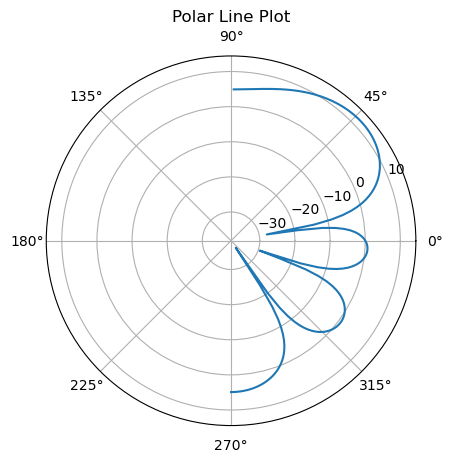

In [ ]:
angle = 42*np.pi/180
d = np.array([0, 0.5, 1, 1.5])
array = np.exp(1j*2*np.pi*d*np.sin(angle))
beam_strength = np.zeros([180])
theta_search = np.arange(-np.pi/2, np.pi/2, 1*np.pi/180)
for i in range(0, len(theta_search)):
    beam_strength[i] = np.abs(np.sum(array*np.exp(-1j*2*np.pi*d*np.sin(theta_search[i]))))**2

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta_search, 10*np.log10(beam_strength))
ax.set_title("Polar Line Plot")
plt.show()

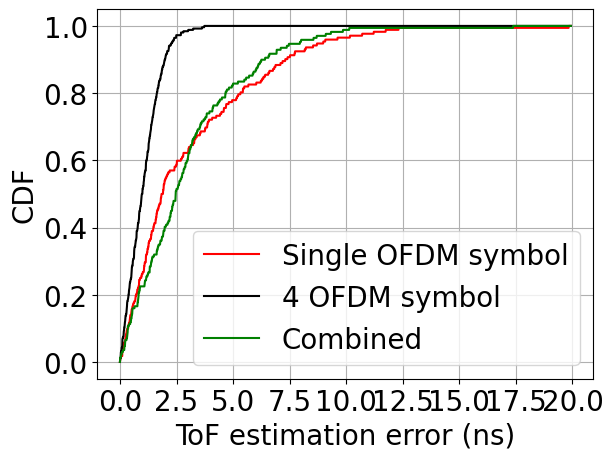

In [30]:
max_val = np.max(np.array([np.max(err_tau), np.max(err_tau_1), np.max(err_tau_4)]))

x = np.arange(0, max_val+0.1, 0.01)
cdf_0 = cal_cdf(err_tau[err_tau != 0], x)

# x = np.arange(0, max_val+0.1, 0.01)
cdf_1 = cal_cdf(err_tau_1[err_tau_1 != 0], x)

# x = np.arange(0, max_val+0.1, 0.01)
cdf_4 = cal_cdf(err_tau_4[err_tau_4 != 0], x)

plt.plot(x, cdf_1, label='Single OFDM symbol', color='red')
plt.plot(x, cdf_4, label='4 OFDM symbol', color='black')
plt.plot(x, cdf_0, label='Combined', color='green')
plt.xlabel('ToF estimation error (ns)', fontsize=20)
plt.ylabel('CDF', fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid()
plt.legend(fontsize=20)